# ¿Cuánto cambia el F1 con el protocolo? Partición aleatoria 70–30 contra LOSO

**Pregunta:** el artículo de referencia que usa este mismo dataset reporta un F1 de **95.7 %** (BiLSTM) con una partición **aleatoria 70–30 de las ventanas** de todos los sujetos, y de **90.3 %** al entrenar con 13 sujetos y probar con uno nuevo. Nuestro modelo obtiene **0.873** (CPC-GRU) y **0.892** (RF) con LOSO. ¿Cuánto de esa diferencia se debe al **protocolo** y no al modelo?

**Diseño:** el mismo modelo y los mismos datos que en el notebook 11; sólo cambia cómo se dividen las ventanas.

| | LOSO (notebook 11) | 70–30 aleatorio (este notebook) |
|---|---|---|
| Prueba | todas las ventanas de **un sujeto que el modelo nunca vio** | 30 % de las ventanas, elegidas al azar entre **todos** los sujetos |
| Entrenamiento | los 10 sujetos restantes | el 70 % restante de las ventanas de los mismos sujetos |
| Lo que mide | reconocer a una **persona nueva** | reconocer ventanas de **personas y ensayos que ya vio** |

- **Datos:** sujetos 1–12, subconjunto `EML` (10 variables), ventanas de 4 s con una ventana etiquetada cada 0.5 s (las del notebook 11). Los sujetos 13 y 14 siguen reservados para la prueba final. El artículo usa los 14 sujetos.
- **Partición:** 70 % entrenamiento y 30 % prueba, al azar y estratificada por actividad. Del 70 % de entrenamiento se separa al azar un 15 % como validación, para la parada temprana de CPC y del ajuste fino (el artículo entrena un número fijo de épocas).
- **Sin fuga por preprocesamiento:** el escalador se ajusta sólo con los instantes de las ventanas de entrenamiento, y CPC se preentrena sólo con ventanas de entrenamiento.
- **Modelos:** CPC-GRU + LP-FT (el del notebook 11, entrenado desde cero en cada partición) y el Random Forest (el del notebook 11).
- **3 semillas,** como el artículo (3 entrenamientos por configuración). Cada semilla cambia la partición y la inicialización.

**Qué se espera.** Con ventanas de 4 s cada 0.5 s, dos ventanas vecinas comparten el 87.5 % de sus datos. En una partición aleatoria, casi toda ventana de prueba tiene una vecina casi idéntica en entrenamiento. La sección 5 mide cuántas. El artículo usa ventanas de 1 s sin traslape, así que en él esta fuga es menor; aun así conserva la de "mismas personas y mismos ensayos".

**Parte B (secciones 10–14):** el mismo ejercicio con las ventanas del artículo (1 s, sin traslape) y con las 30 variables + la sEMG, en 70–30 y en LOSO. Las conclusiones de la sección 9 son sólo de la parte A.

**Tiempo estimado:** el RF, unos minutos; CPC-GRU, 3 particiones × ≈ 10–25 min.

# 1. Configuración

In [1]:
import copy, json, os, re, time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Datos y validación (iguales al avance 5) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # ventanas de la sonda que decide la parada temprana de CPC (como el notebook 10)

# ----------------------------- Random Forest (el del notebook 11) -----------------------------
RF_PARAMS = dict(n_estimators=300, max_features="sqrt", min_samples_leaf=2, class_weight="balanced_subsample",
                 n_jobs=-1, random_state=SEED)          # el del avance 4

# ----------------------------- CPC-GRU + LP-FT (los valores de los notebooks 10 y 11) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (1 s)
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
FT_EPOCHS, FT_PATIENCE = 30, 5         # etapa FT de LP-FT
LP_EPOCHS, LP_PATIENCE, LP_LR = 20, 3, 1e-3   # etapa LP de LP-FT
STEPS_CAP = FT_TRAIN_CAP = None        # límites sólo para la corrida de prueba

# ----------------------------- Partición aleatoria (como el artículo) -----------------------------
TEST_FRAC = 0.30                       # 70 % entrenamiento, 30 % prueba
VAL_FRAC = 0.15                        # fracción del 70 % de entrenamiento que se usa como validación (parada temprana)
SPLIT_SEEDS = (0, 1, 2)                # 3 repeticiones, como el artículo

# Corrida de prueba rápida (1 partición, pocas épocas) para revisar que todo funciona: NB15_QUICK=1
QUICK = os.environ.get("NB15_QUICK") == "1"
FOLDS = CV_SUBJECTS
if QUICK:
    SPLIT_SEEDS = (0,)
    RF_PARAMS = {**RF_PARAMS, "n_estimators": 30}
    CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE, STEPS_CAP = 2, 1, 1, 5
    PROBE_TRAIN_MAX, FT_TRAIN_CAP, LP_EPOCHS, FT_EPOCHS = 2_000, 2_000, 1, 1

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas del notebook 10 (30 variables)
NB11_DIR = REPO_DIR / "checkpoints" / f"nb11_variables_minimas_fs{TARGET_FS}"          # resultados LOSO del notebook 11
RUN_DIR = REPO_DIR / "checkpoints" / (f"nb15_particion_70_30_fs{TARGET_FS}" + ("_quick" if QUICK else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"
assert SAVED_DIR.exists(), f"Faltan las rondas del notebook 10 en {SAVED_DIR.relative_to(REPO_DIR)}"
assert (NB11_DIR / "rf" / "EML.json").exists() and (NB11_DIR / "gru_ft" / "EML").exists(), \
    f"Faltan los resultados EML del notebook 11 en {NB11_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | particiones: {len(SPLIT_SEEDS)} | QUICK: {QUICK}")
print(f"Resultados en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | particiones: 3 | QUICK: False
Resultados en: checkpoints/nb15_particion_70_30_fs12


# 2. Datos

Los mismos del notebook 11: MVNX a 12 Hz, las 30 variables de Xsens, etiqueta del instante final, ventanas de 4 s y los 3 ensayos recuperados del sujeto 7. Un cambio menor: el escalador puede ajustarse con una lista de instantes (los de las ventanas de entrenamiento) en lugar de con sujetos completos.

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]          # posiciones (m)
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]               # velocidades (m/s)
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]                            # giros (rad/s)
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]               # flexiones (°)
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]   # hombros en XZY
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]            # contactos (0/1)
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}   # nombre de columna -> posición
SIDES = (("izq", "Left"), ("der", "Right"))           # prefijo en español y nombre del lado en el MVNX


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    # --- Postura (14): ángulos articulares en grados ---
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    # --- Alturas y alcance (6): en metros; el alcance es la distancia horizontal mano–pelvis ---
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    # --- Velocidades (6): normas, para que no dependan de hacia dónde mira la persona ---
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    # --- Apoyo (4): contacto del talón y la punta de cada pie con el suelo ---
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


# Unidad y grupo de cada variable (se usan en tablas, en el escalador y en la gráfica de importancia)
def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())   # excluido sólo por sEMG
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"                 # espacio de nombres del XML de Xsens
# Campos que se leen y cómo se remuestrea cada uno
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
# Nombre de archivo -> sujeto, tarea, lado, carga y condición
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    # El XML pesa cientos de MB: se lee por eventos y cada frame se borra después de leerlo
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))                     # nombres de segmentos, articulaciones y contactos
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":                         # se ignoran los frames de calibración
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


# Nombres de columna de un campo, con el mismo formato que la exportación sincronizada
def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


# Pasa-bajas antialias de fase cero (Butterworth de orden 4 a 4.8 Hz) antes de bajar de 240 a 12 Hz
def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# Vecino más cercano: para contactos (0/1) y etiquetas, que no se pueden interpolar
def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


# Remuestrea un campo a la rejilla de 12 Hz según su tipo
def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))              # evita saltos de 180° a −180° al filtrar
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


# Etiquetas válidas: actividades conocidas, segmentos con inicio antes del fin y sin traslapes
def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    # Controles de calidad: saltos de tiempo en la grabación y etiquetas consistentes
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    # Etiqueta de cada frame a partir de los segmentos anotados (en frames de MVNX)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

# Se conservan sólo los recuperados que pasan los mismos controles que el resto del MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    # Exportación sincronizada de cada conjunto de ensayos: series a 12 Hz y tabla de ensayos
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])                                # 782 columnas -> 30 variables
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx
# Se agregan al final los ensayos recuperados de la sección anterior
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])                             # fila donde empieza cada ensayo
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]   # contactos: el escalador no los modifica
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


In [5]:
# Índices de ventanas: no se copian los datos, sólo se guarda dónde empieza cada ventana
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:                                            # ensayo más corto que una ventana
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        # Ventanas sin etiqueta para CPC: una cada CPC_HOP pasos (2 s)
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        # Ventanas etiquetadas: una cada SUP_HOP pasos (0.5 s), con la etiqueta del instante final; sin etiqueta se descartan
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")


# Entrada del Random Forest: 5 estadísticas de cada variable en la ventana
STATS = ("media", "desv", "min", "max", "pendiente")
T_CENTERED = np.arange(WIN) - (WIN - 1) / 2                   # tiempo centrado, para calcular la pendiente


def window_stats(starts, chunk=8_192):
    """Las 5 estadísticas de cada variable en cada ventana -> (ventanas, 150), en unidades físicas."""
    view = sliding_window_view(signals_raw, WIN, axis=0)          # (instantes − WIN + 1, 30, WIN), sin copiar
    out = []
    for i in range(0, len(starts), chunk):                        # por bloques, para no llenar la memoria
        w = view[starts[i:i + chunk]].astype(np.float64)
        slope = (w * T_CENTERED).sum(axis=2) / (T_CENTERED ** 2).sum() * TARGET_FS   # pendiente por mínimos cuadrados, por segundo
        out.append(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1))
    return np.concatenate(out).astype(np.float32)


# Escalador de las redes: se ajusta en cada ronda sólo con los sujetos de entrenamiento (sin fuga del sujeto evaluado)
def fit_scaler(train_subjects=None, seed=SEED, idx=None):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento (o con los instantes `idx`). Contactos (0/1): sin cambio."""
    if idx is None:
        rows = trials[trials["subject"].isin(train_subjects)]
        idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    # Recorte en los cuantiles 0.1 % y 99.9 %, luego (x − mediana) / (q95 − q5)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)


# Tabla de 150 características por ventana etiquetada, para el Random Forest
TABULAR_COLUMNS = [f"{s}_{n}" for s in STATS for n in CHANNELS]
X_tab = pd.DataFrame(window_stats(starts_of(sup_cv)), index=sup_cv.index, columns=TABULAR_COLUMNS)
print(f"Random Forest -> X_tab: {X_tab.shape}  (ventanas, {len(STATS)} estadísticas × {N_CH} variables)")

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498
Random Forest -> X_tab: (40944, 150)  (ventanas, 5 estadísticas × 30 variables)


# 3. Subconjunto

Los grupos del notebook 11 y el subconjunto `EML` (codos, manos y piernas): 10 variables, 11 sensores. La celda de protocolo del notebook 11 se incluye porque define funciones que se reutilizan (`eval_set`, `summarize`) y comprueba que las ventanas son las mismas.

In [6]:
SENSORS_ALL = ("Pelvis", "T8", "Head", "LeftShoulder", "RightShoulder", "LeftUpperArm", "RightUpperArm", "LeftForeArm",
               "RightForeArm", "LeftHand", "RightHand", "LeftUpperLeg", "RightUpperLeg", "LeftLowerLeg", "RightLowerLeg",
               "LeftFoot", "RightFoot")
both = lambda *names: [f"{lado}_{n}" for n in names for lado in ("izq", "der")]   # izquierda y derecha siempre juntas
pair = lambda *segments: [f"{side}{s}" for s in segments for side in ("Left", "Right")]

# Código -> nombre, variables y sensores que necesita. El orden es el de la tabla.
GROUPS = {
    "G": {"nombre": "Posiciones globales", "variables": ["pelvis_altura", "cabeza_altura"] + both("mano_altura", "mano_alcance"),
          "sensores": list(SENSORS_ALL)},
    "P": {"nombre": "Pelvis", "variables": ["pelvis_vel_horizontal", "pelvis_vel_vertical", "pelvis_giro"],
          "sensores": ["Pelvis"]},
    "T": {"nombre": "Tronco", "variables": ["tronco_flexion", "tronco_vel_angular"], "sensores": ["Pelvis", "T8"]},
    "C": {"nombre": "Cabeza", "variables": ["cuello_flexion"], "sensores": ["T8", "Head"]},
    "H": {"nombre": "Hombros", "variables": both("hombro_flexion", "hombro_abduccion"),
          "sensores": pair("Shoulder", "UpperArm")},
    "E": {"nombre": "Codos", "variables": both("codo_flexion"), "sensores": pair("UpperArm", "ForeArm")},
    "M": {"nombre": "Manos", "variables": both("muneca_flexion", "mano_rapidez"), "sensores": pair("ForeArm", "Hand")},
    "L": {"nombre": "Piernas", "variables": both("cadera_flexion", "rodilla_flexion"),
          "sensores": ["Pelvis"] + pair("UpperLeg", "LowerLeg")},
    "F": {"nombre": "Pies", "variables": both("talon", "punta"), "sensores": pair("LowerLeg", "Foot")},
}
# Control: los grupos reparten las 30 variables sin repetir ninguna, y sólo usan sensores del traje
grouped = [v for g in GROUPS.values() for v in g["variables"]]
assert sorted(grouped) == sorted(CHANNELS) and len(grouped) == len(set(grouped)), "Los grupos no cubren las 30 variables"
assert all(set(g["sensores"]) <= set(SENSORS_ALL) for g in GROUPS.values())


def subset_key(groups):
    """Nombre corto de un subconjunto: los códigos de sus grupos en el orden de GROUPS (p. ej. 'PTEM')."""
    return "".join(g for g in GROUPS if g in groups)


def variables_of(groups):
    """Variables de un subconjunto, en el orden de CHANNELS."""
    keep = {v for g in groups for v in GROUPS[g]["variables"]}
    return [c for c in CHANNELS if c in keep]


def sensors_of(groups):
    return sorted({s for g in groups for s in GROUPS[g]["sensores"]}, key=SENSORS_ALL.index)



SUBSET = ("E", "M", "L")                 # codos, manos y piernas: el mínimo del notebook 11
VARS = variables_of(SUBSET)
COLS = [CHANNELS.index(v) for v in VARS]
print(f"{subset_key(SUBSET)}: {len(VARS)} variables: {', '.join(VARS)}")

EML: 10 variables: izq_codo_flexion, izq_muneca_flexion, izq_cadera_flexion, izq_rodilla_flexion, der_codo_flexion, der_muneca_flexion, der_cadera_flexion, der_rodilla_flexion, izq_mano_rapidez, der_mano_rapidez


In [7]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    """(sujeto de validación interna, sujetos de entrenamiento) de la ronda en la que se evalúa `held_out`."""
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def eval_set(frame, cap=None):
    """Ventanas de un conjunto. Con `cap`, una muestra estratificada por actividad (la misma del notebook 10)."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(held_out):
    """Conjuntos de la ronda: sonda (parada temprana de CPC), ajuste fino, validación interna y sujeto evaluado."""
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


def nb10_round(folder, held_out):
    """Resultado guardado de una ronda del notebook 10 (predicciones, tiempos, escalador)."""
    return json.loads((SAVED_DIR / folder / f"ronda_s{held_out:02d}_semilla0.json").read_text())


def summarize(f1):
    """Resumen entre sujetos de un vector de F1 por ronda."""
    f1 = np.asarray(f1)
    return {"f1": f1.mean(), "desv": f1.std(ddof=1) if len(f1) > 1 else 0.0, "peor": f1.min()}


# Control: las ventanas evaluadas aquí son las mismas que evaluó el notebook 10 en cada ronda
for s in FOLDS:
    assert nb10_round("GRU/h1s_lpft", s)["index"] == sup_cv.index[sup_cv["subject"] == s].tolist(), f"Ventanas distintas, sujeto {s}"
print("Las ventanas de los sujetos evaluados coinciden con las del notebook 10.")

Las ventanas de los sujetos evaluados coinciden con las del notebook 10.


# 4. Partición aleatoria 70–30

Las ventanas etiquetadas de los sujetos 1–12 se dividen al azar, estratificando por actividad: 30 % prueba, y del 70 % restante, un 15 % validación y el resto entrenamiento. Cada semilla da una partición distinta.

In [8]:
def split_70_30(seed):
    """Índices (de sup_cv) de entrenamiento, validación y prueba de una partición aleatoria estratificada por actividad."""
    train_val, test = train_test_split(sup_cv.index, test_size=TEST_FRAC, stratify=sup_cv["target"], random_state=seed)
    train, val = train_test_split(train_val, test_size=VAL_FRAC, stratify=sup_cv.loc[train_val, "target"], random_state=seed)
    return train, val, test


rows = []
for seed in SPLIT_SEEDS:
    tr, va, te = split_70_30(seed)
    assert not (set(tr) & set(te)) and not (set(va) & set(te)) and not (set(tr) & set(va))
    rows.append({"semilla": seed, "entrenamiento": len(tr), "validación": len(va), "prueba": len(te),
                 "sujetos en prueba": sup_cv.loc[te, "subject"].nunique()})
display(pd.DataFrame(rows).set_index("semilla"))

,entrenamiento,validación,prueba,sujetos en prueba
semilla,,,,
0,24361,4299,12284,12
1,24361,4299,12284,12
2,24361,4299,12284,12


# 5. ¿Qué tan parecidas son las ventanas de prueba a las de entrenamiento?

Para cada ventana de prueba se busca la ventana de entrenamiento (o validación) más cercana **del mismo ensayo** y se calcula qué fracción de sus 48 instantes comparten. En LOSO esta fracción es siempre 0: el sujeto de prueba no aparece en entrenamiento.

In [9]:
def overlap_with_train(train_idx, test_idx):
    """Para cada ventana de prueba, fracción de instantes que comparte con la ventana de entrenamiento más cercana del mismo ensayo."""
    tr, te = sup_cv.loc[train_idx], sup_cv.loc[test_idx]
    by_trial = {t: np.sort(g["start_step"].to_numpy()) for t, g in tr.groupby("trial_idx")}
    out = np.zeros(len(te))
    for i, (t, s) in enumerate(zip(te["trial_idx"].to_numpy(), te["start_step"].to_numpy())):
        starts = by_trial.get(t)
        if starts is None:
            continue
        j = np.searchsorted(starts, s)
        gap = min(abs(starts[k] - s) for k in (j - 1, j) if 0 <= k < len(starts))
        out[i] = max(0, WIN - gap) / WIN
    return out


tr, va, te = split_70_30(SPLIT_SEEDS[0])
overlap = overlap_with_train(tr.append(va), te)
display(pd.DataFrame({
    "ventanas de prueba con una vecina de entrenamiento que comparte…": ["≥ 87.5 % de los instantes (a 0.5 s)", "≥ 75 % (a 1 s o menos)",
                                                                         "≥ 50 % (a 2 s o menos)", "algún instante"],
    "% de las ventanas de prueba": [100 * (overlap >= 0.875).mean(), 100 * (overlap >= 0.75).mean(),
                                    100 * (overlap >= 0.5).mean(), 100 * (overlap > 0).mean()]})
    .set_index("ventanas de prueba con una vecina de entrenamiento que comparte…").style.format("{:.1f}"))
print(f"Instantes compartidos con la vecina más cercana: mediana {100 * np.median(overlap):.1f} %")

,% de las ventanas de prueba
ventanas de prueba con una vecina de entrenamiento que comparte…,
≥ 87.5 % de los instantes (a 0.5 s),90.9
≥ 75 % (a 1 s o menos),99.1
≥ 50 % (a 2 s o menos),100.0
algún instante,100.0


Instantes compartidos con la vecina más cercana: mediana 87.5 %


# 6. Random Forest

El del notebook 11 (300 árboles, 5 estadísticas de cada una de las 10 variables). Como no usa parada temprana, se entrena con entrenamiento + validación (el 70 %) y se evalúa en el 30 % de prueba.

In [10]:
RF_COLS = [f"{s}_{n}" for s in STATS for n in VARS]
X_rf, y_rf = X_tab[RF_COLS], sup_cv["target"]


def run_rf_split(seed):
    path = RUN_DIR / "rf_70_30" / f"semilla{seed}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    tr, va, te = split_70_30(seed)
    train = tr.append(va)
    t0 = time.time()
    clf = RandomForestClassifier(**{**RF_PARAMS, "random_state": seed}).fit(X_rf.loc[train].to_numpy(), y_rf.loc[train].to_numpy())
    y, pred = y_rf.loc[te].to_numpy(), clf.predict(X_rf.loc[te].to_numpy())
    res = {"semilla": seed, "f1": f1_score(y, pred, average="macro"), "minutos": (time.time() - t0) / 60,
           "index": te.tolist(), "y": y.tolist(), "pred": pred.tolist()}
    path.write_text(json.dumps(res))
    log(f"RF · 70–30 · semilla {seed} | F1 {res['f1']:.3f}")
    return res


rf_runs = {seed: run_rf_split(seed) for seed in SPLIT_SEEDS}

2026-11-08 23:09 | RF · 70–30 · semilla 0 | F1 0.922
2026-11-08 23:09 | RF · 70–30 · semilla 1 | F1 0.917
2026-11-08 23:09 | RF · 70–30 · semilla 2 | F1 0.919


# 7. CPC-GRU + ajuste fino

El modelo y el procedimiento del notebook 11, entrenados desde cero en cada partición. Lo que cambia es de dónde salen los datos de cada etapa:

| Etapa | LOSO (notebook 11) | 70–30 aleatorio |
|---|---|---|
| Escalador | instantes de los 10 sujetos de entrenamiento | instantes de las ventanas de entrenamiento |
| CPC (sin etiquetas) | ventanas de los 10 sujetos de entrenamiento | ventanas de entrenamiento (negativos del mismo sujeto) |
| Parada temprana | sujeto de validación interna | 15 % de validación |
| Prueba | el sujeto evaluado | el 30 % de prueba |

El número de pasos de CPC por época es proporcional a la cantidad de datos de entrenamiento: ≈ 60 % de las ventanas sin etiqueta de los 12 sujetos (en LOSO, las de los 10 sujetos de entrenamiento).

In [11]:
@dataclass
class CPCConfig:
    n_channels: int = 30
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS
    horizons: tuple = HORIZONS

    @property
    def z_dim(self):
        return self.enc_channels[-1]

    @property
    def c_dim(self):
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: 3 bloques Conv1d -> ReLU -> Dropout, relleno sólo a la izquierda. x: (B, canales, T) -> z: (B, 128, T)"""

    def __init__(self, cfg):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class CPCModel(nn.Module):
    """CPC con g_ar GRU: encoder + GRU + una W_k por horizonte; pérdida InfoNCE con negativos del batch."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers, dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        """x: (B, canales, T) -> z: (B, T, 128), c: (B, T, 256)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def info_nce(self, x):
        z, c = self.encode(x)
        lo, hi = max(1, z.shape[1] // 8), z.shape[1] - max(self.cfg.horizons)   # deja sitio para leer z_{t+12}
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].t()                         # (B, B): la diagonal es el positivo
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()


class CPCClassifier(nn.Module):
    """Encoder y GRU de CPC + cabeza (LayerNorm, Dropout, Linear) sobre c_T, el contexto del último instante."""

    def __init__(self, cpc_model, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        dim = cpc_model.cfg.c_dim
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def features(self, x):
        return self.ar(self.encoder(x).transpose(1, 2))[0][:, -1]

    def forward(self, x):
        return self.head(self.features(x))


def build_cpc(n_channels, seed=SEED):
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels)).to(DEVICE)

In [12]:
# ----------------------------- Serie escalada de la ronda, sólo con las variables del subconjunto -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, variables del subconjunto, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def prepare_round(held_out, groups):
    """Escalador de la ronda (comprobado contra el del notebook 10) y serie del subconjunto en el dispositivo."""
    global S_T
    inner_val, train_subjects, sets, n_steps = make_sets(held_out)
    scaler = fit_scaler(train_subjects)
    saved = nb10_round("GRU/h1s_lpft", held_out)["scaler"]
    assert all(np.allclose(saved[k], scaler[k]) for k in scaler), f"Escalador distinto al del notebook 10, sujeto {held_out}"
    cols = [CHANNELS.index(v) for v in variables_of(groups)]
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler)[:, cols].T)).to(DEVICE)
    return {"held_out": held_out, "inner_val": inner_val, "train_subjects": train_subjects, "sets": sets,
            "n_steps": n_steps, "n_channels": len(cols)}


@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


# ----------------------------- Preentrenamiento CPC (sin etiquetas) -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def probe_val_f1(model, rnd):
    """F1 en la validación interna de una sonda lineal (C = 1) sobre c_T. Decide la parada temprana de CPC."""
    model.eval()
    rep = lambda part: batched(lambda x: model.encode(x)[1][:, -1], rnd["sets"][part]["starts"]).float().cpu().numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    probe.fit(rep("probe_train"), rnd["sets"]["probe_train"]["y"])
    return f1_score(rnd["sets"]["val"]["y"], probe.predict(rep("val")), average="macro")


def train_cpc(rnd, seed=SEED):
    t0 = time.time()
    model = build_cpc(rnd["n_channels"], seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = rnd["sampler"](seed) if "sampler" in rnd else SameSubjectSampler(rnd["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))             # pérdida contrastiva: no usa etiquetas
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            f1_val = probe_val_f1(model, rnd)
            if f1_val > best["f1"] + 1e-4:
                best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


# ----------------------------- LP-FT (con etiquetas) -----------------------------
def linear_probe_head(model, sets, seed):
    """Etapa LP: entrena sólo la cabeza con el encoder y la GRU congelados."""
    model.eval()
    X_tr, X_val = batched(model.features, sets["ft_train"]["starts"]), batched(model.features, sets["val"]["starts"])
    y_tr = torch.as_tensor(np.array(sets["ft_train"]["y"]), device=DEVICE)
    weights = class_weights(sets["ft_train"]["y"])
    opt = torch.optim.AdamW(model.head.parameters(), lr=LP_LR, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    best, bad = {"f1": -1.0, "state": copy.deepcopy(model.head.state_dict())}, 0
    for epoch in range(1, LP_EPOCHS + 1):
        model.head.train()
        order = rng.permutation(len(y_tr))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = torch.as_tensor(order[s:s + FINETUNE_BATCH], device=DEVICE)
            loss = F.cross_entropy(model.head(X_tr[idx]), y_tr[idx], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.head.eval()
        with torch.no_grad():
            f1_val = f1_score(sets["val"]["y"], model.head(X_val).argmax(1).cpu().numpy(), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "state": copy.deepcopy(model.head.state_dict())}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.head.load_state_dict(best["state"])
    return best["f1"]


def finetune(cpc_model, sets, seed=SEED):
    """LP-FT: la cabeza de LP es el punto de partida (época 0) y después se ajusta toda la red."""
    t0 = time.time()
    torch.manual_seed(seed)
    model = CPCClassifier(cpc_model).to(DEVICE)
    best = {"f1": linear_probe_head(model, sets, seed), "epoch": 0, "state": copy.deepcopy(model.state_dict())}
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng, bad = np.random.default_rng(seed), 0
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FT_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}

In [13]:
class TrainWindowSampler:
    """Batches de CPC: ventanas de entrenamiento de UN solo sujeto (como SameSubjectSampler, pero sólo de la partición de entrenamiento)."""

    def __init__(self, frame, seed):
        self.rng = np.random.default_rng(seed)
        starts, subj = starts_of(frame), frame["subject"].to_numpy()
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def prepare_split(seed):
    """Conjuntos, escalador (sólo con instantes de entrenamiento) y serie escalada de una partición 70–30."""
    global S_T
    tr, va, te = split_70_30(seed)
    train = sup_cv.loc[tr]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv.loc[va]), "held": eval_set(sup_cv.loc[te])}
    covered = np.unique((starts_of(train)[:, None] + np.arange(WIN)).ravel())       # instantes de las ventanas de entrenamiento
    scaler = fit_scaler(idx=covered)
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler)[:, COLS].T)).to(DEVICE)
    n_steps = max(1, round(len(cpc_cv) * (1 - TEST_FRAC) * (1 - VAL_FRAC)) // CPC_BATCH)
    return {"seed": seed, "sets": sets, "n_channels": len(COLS), "sampler": lambda s: TrainWindowSampler(train, s),
            "n_steps": min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps}


def run_gru_split(seed):
    """CPC + LP-FT en una partición 70–30. Se guarda al terminar y se carga si ya existe."""
    path = RUN_DIR / "gru_70_30" / f"semilla{seed}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    rnd = prepare_split(seed)
    cpc_model, info_cpc = train_cpc(rnd, seed=seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())                        # el ajuste fino modifica la red en su lugar
    model, info_ft = finetune(cpc_model, rnd["sets"], seed=seed)
    held, train = rnd["sets"]["held"], rnd["sets"]["ft_train"]
    pred = predict(model, held["starts"])
    res = {"semilla": seed, "f1": f1_score(held["y"], pred, average="macro"),
           "f1_train": f1_score(train["y"], predict(model, train["starts"]), average="macro"),
           "cpc": info_cpc, "ajuste_fino": info_ft, "minutos": info_cpc["minutes"] + info_ft["minutes"],
           "index": held["index"].tolist(), "y": held["y"].tolist(), "pred": pred.tolist()}
    torch.save({"cpc": cpc_state, "ajuste_fino": model.state_dict(), "variables": VARS}, path.with_suffix(".pt"))
    path.write_text(json.dumps(res))
    log(f"GRU · 70–30 · semilla {seed} | F1 {res['f1']:.3f} (entr. {res['f1_train']:.3f}) | {res['minutos']:.1f} min")
    del cpc_model, model
    return res


gru_runs = {seed: run_gru_split(seed) for seed in SPLIT_SEEDS}

2026-11-08 23:13 | GRU · 70–30 · semilla 0 | F1 0.897 (entr. 0.900) | 3.6 min
2026-11-08 23:19 | GRU · 70–30 · semilla 1 | F1 0.905 (entr. 0.919) | 5.3 min
2026-11-08 23:23 | GRU · 70–30 · semilla 2 | F1 0.896 (entr. 0.904) | 4.4 min


# 8. Comparativo

## 8.1 F1 por protocolo

F1 macro de cada modelo con cada protocolo. En LOSO: media y desviación entre los 12 sujetos evaluados (notebook 11). En 70–30: media y desviación entre las 3 particiones. Abajo, los valores del artículo como referencia; su modelo, sus variables (incluyen sEMG) y sus ventanas (1 s sin traslape) son distintos.

In [14]:
loso = {"CPC-GRU + ajuste fino": np.array([json.loads((NB11_DIR / "gru_ft" / "EML" / f"ronda_s{s:02d}.json").read_text())["f1"]
                                           for s in CV_SUBJECTS]),
        "Random Forest": np.array(list(json.loads((NB11_DIR / "rf" / "EML.json").read_text())["f1"].values()))}
split = {"CPC-GRU + ajuste fino": np.array([gru_runs[s]["f1"] for s in SPLIT_SEEDS]),
         "Random Forest": np.array([rf_runs[s]["f1"] for s in SPLIT_SEEDS])}
sd = lambda a: a.std(ddof=1) if len(a) > 1 else np.nan

rows = []
for model in split:
    rows.append({"modelo": model, "LOSO (sujeto nuevo)": loso[model].mean(), "desv. LOSO": sd(loso[model]),
                 "70–30 aleatorio": split[model].mean(), "desv. 70–30": sd(split[model]),
                 "diferencia (70–30 − LOSO)": split[model].mean() - loso[model].mean()})
display(pd.DataFrame(rows).set_index("modelo").style.format("{:.3f}", na_rep="—"))

display(pd.DataFrame({"LOSO (13 sujetos → sujeto 14)": [0.903, 0.892], "70–30 aleatorio": [0.957, 0.959]},
                     index=pd.Index(["BiLSTM", "RCNN"], name="artículo de referencia"))
        .assign(**{"diferencia (70–30 − LOSO)": lambda d: d["70–30 aleatorio"] - d["LOSO (13 sujetos → sujeto 14)"]})
        .style.format("{:.3f}"))

,LOSO (sujeto nuevo),desv. LOSO,70–30 aleatorio,desv. 70–30,diferencia (70–30 − LOSO)
modelo,,,,,
CPC-GRU + ajuste fino,0.873,0.036,0.900,0.005,0.027
Random Forest,0.892,0.029,0.919,0.003,0.028


,LOSO (13 sujetos → sujeto 14),70–30 aleatorio,diferencia (70–30 − LOSO)
artículo de referencia,,,
BiLSTM,0.903,0.957,0.054
RCNN,0.892,0.959,0.067


## 8.2 F1 por clase

F1 de cada actividad con CPC-GRU: LOSO (todas las ventanas de los 12 sujetos evaluados juntas) contra 70–30 (las ventanas de prueba de las 3 particiones juntas). Muestra en qué actividades sube más el F1 cuando el modelo ya vio a la persona.

In [15]:
def pooled(runs, key):
    return np.concatenate([np.asarray(r[key]) for r in runs])


loso_runs = [json.loads((NB11_DIR / "gru_ft" / "EML" / f"ronda_s{s:02d}.json").read_text()) for s in CV_SUBJECTS]
per_class = pd.DataFrame({
    "GRU LOSO": f1_score(pooled(loso_runs, "y"), pooled(loso_runs, "pred"), average=None, labels=range(len(LABELS))),
    "GRU 70–30": f1_score(pooled(gru_runs.values(), "y"), pooled(gru_runs.values(), "pred"), average=None, labels=range(len(LABELS))),
    "RF 70–30": f1_score(pooled(rf_runs.values(), "y"), pooled(rf_runs.values(), "pred"), average=None, labels=range(len(LABELS)))},
    index=pd.Index(LABELS, name="clase"))
per_class["GRU: 70–30 − LOSO"] = per_class["GRU 70–30"] - per_class["GRU LOSO"]
display(per_class.style.format("{:.3f}"))

train_f1 = np.array([gru_runs[s]["f1_train"] for s in SPLIT_SEEDS])
print(f"CPC-GRU en 70–30: F1 en entrenamiento {train_f1.mean():.3f} | F1 en prueba {split['CPC-GRU + ajuste fino'].mean():.3f}")

,GRU LOSO,GRU 70–30,RF 70–30,GRU: 70–30 − LOSO
clase,,,,
N,0.917,0.927,0.947,0.010
LF,0.837,0.875,0.906,0.038
K,0.914,0.928,0.937,0.014
PT,0.821,0.853,0.879,0.032
LT,0.823,0.866,0.887,0.042
W,0.933,0.947,0.954,0.014
PF,0.889,0.901,0.926,0.012


CPC-GRU en 70–30: F1 en entrenamiento 0.908 | F1 en prueba 0.900


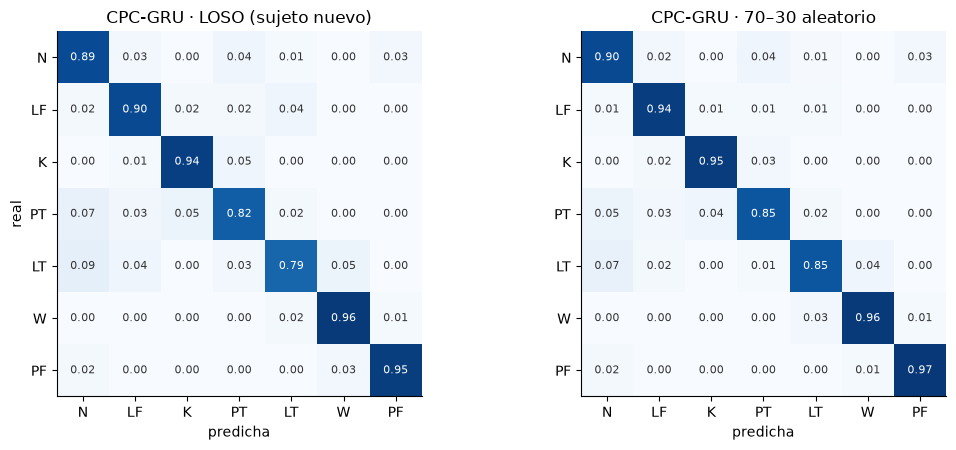

In [16]:
# Matrices de confusión de CPC-GRU (filas: actividad real, normalizadas por fila): LOSO contra 70–30
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (title, runs) in zip(axes, [("LOSO (sujeto nuevo)", loso_runs), ("70–30 aleatorio", list(gru_runs.values()))]):
    cm = confusion_matrix(pooled(runs, "y"), pooled(runs, "pred"), labels=range(len(LABELS)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.6 else "#333")
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("predicha")
    ax.set_title(f"CPC-GRU · {title}")
axes[0].set_ylabel("real")
plt.tight_layout()
plt.show()

# 9. Conclusiones

**Respuesta corta:** con la partición aleatoria 70–30 el F1 sube sólo **≈ 3 puntos** (CPC-GRU 0.873 → **0.900**, RF 0.892 → **0.919**). No llegamos al 95.7 % del artículo, aunque aquí la fuga entre entrenamiento y prueba es **mayor** que en el artículo. La diferencia con el artículo no se explica sólo por el protocolo: con nuestras ventanas y nuestras 10 variables, el techo está en ≈ 0.90–0.92 aunque el modelo ya haya visto a la persona y a casi la misma ventana.

| | LOSO | 70–30 aleatorio | diferencia |
|---|---|---|---|
| CPC-GRU + ajuste fino (nuestro) | 0.873 ± 0.036 | 0.900 ± 0.005 | +0.027 |
| Random Forest (nuestro) | 0.892 ± 0.029 | 0.919 ± 0.003 | +0.028 |
| BiLSTM (artículo) | 0.903 (13 → 14) | 0.957 | +0.054 |
| RCNN (artículo) | 0.892 (13 → 14) | 0.959 | +0.067 |

## 9.1 La fuga existe y es casi total

- El **90.9 %** de las ventanas de prueba tiene en entrenamiento una vecina del mismo ensayo que comparte el 87.5 % de sus instantes (está a 0.5 s), el 99.1 % una que comparte ≥ 75 % y el **100 %** una que comparte al menos la mitad.
- En la práctica, el 70–30 evalúa al modelo sobre ventanas que ya vio casi completas. Por eso **no es una medida de generalización a personas nuevas**, que es lo que necesita la aplicación; LOSO sí lo es.

## 9.2 Aun así, el F1 casi no sube: el límite no es el modelo ni el protocolo

- **El modelo no memoriza.** F1 en entrenamiento 0.908 contra 0.900 en prueba: las ventanas de prueba son casi copias de las de entrenamiento y aun así el modelo falla en ellas tanto como en las que aprendió. Si el problema fuera de capacidad o de generalización entre personas, el 70–30 lo habría hecho desaparecer.
- **El RF tampoco pasa de 0.92**, con un método totalmente distinto. Dos modelos diferentes topan en el mismo lugar: el límite está en los datos tal como los planteamos (variables y etiquetado), no en la arquitectura.
- **Los errores son los mismos que en LOSO.** Las confusiones principales de CPC-GRU siguen siendo LT → N (7.3 %), PT → N (5.3 %), PT → K (4.4 %) y LT → W (4.0 %); PT, LT y LF siguen siendo las clases con menor F1 (0.853, 0.866, 0.875). Ver a la persona ayuda un poco en esas clases (+3 a +4 puntos), pero no cambia el patrón.
- Esto concuerda con el notebook 14: el **89.6 %** de las ventanas de 4 s contiene una transición entre actividades y se etiqueta con el último instante. Una parte de las ventanas es ambigua por construcción, sin importar cómo se dividan.

## 9.3 Por qué el artículo sí llega a ≈ 96 %

Con este experimento se puede separar lo que aporta cada factor:

1. **Protocolo:** en el artículo el 70–30 aporta +5.4 a +6.7 puntos; en el nuestro, +2.7. El protocolo explica parte de su 95.7 %, pero no la diferencia con nosotros.
2. **Variables:** el artículo usa todos los segmentos de Xsens **y la sEMG**; nosotros, 10 variables de 11 sensores. Es el factor más probable para la diferencia restante.
3. **Ventanas:** usan ventanas de 1 s sin traslape. Una ventana corta contiene menos transiciones y su etiqueta es menos ambigua, lo que sube el techo de cualquier modelo.
4. **En LOSO estamos al nivel del artículo:** su 0.903 (13 sujetos → sujeto 14, un solo sujeto) está dentro del rango de nuestros sujetos en LOSO (0.775–0.908, con 10 sujetos de entrenamiento y 10 variables). Con el protocolo que importa para la aplicación, la diferencia es pequeña.

## 9.4 Qué significa para el proyecto

- **El 95.7 % del artículo no es un objetivo comparable.** Mide otra cosa (ventanas casi repetidas de personas conocidas) con más sensores. Si se reporta, debe ir junto a su 90.3 % de sujeto nuevo, que es el número comparable con nuestro LOSO.
- **Mantener LOSO como protocolo principal.** El 70–30 sólo sirve para mostrar que la comparación con el artículo está hecha en igualdad de condiciones.
- **El RF sigue por encima de CPC-GRU** con los dos protocolos (≈ +2 puntos), y en el 70–30 en todas las clases. Los notebooks 13, 14 y 15 descartan que esto se deba a la cabeza, al pooling o a falta de datos de la misma persona.
- **Las palancas que quedan** son las que cambian los datos, no el modelo: añadir la sEMG o más variables, y una ventana o un etiquetado más cortos que se ajusten a la duración de las acciones (≈ 2 s).
- Detalle menor: en 2 de 3 particiones CPC paró en la época 20 (el máximo) y en una el ajuste fino en la 28 de 30. Más épocas podrían dar algunas milésimas, pero no cambian la conclusión, porque el F1 de entrenamiento ya está pegado al de prueba.

# Parte B — Ventanas de 1 s sin traslape, con las 30 variables + sEMG

**Pregunta:** la parte A usó nuestras ventanas (4 s, una cada 0.5 s) y sólo 10 variables. Si nos acercamos más al artículo, con **ventanas de 1 s sin traslape** y **todas las variables más la sEMG**, ¿cuánto sube el F1 en 70–30 y en LOSO?

| | Parte A | Parte B | Artículo |
|---|---|---|---|
| Ventana | 4 s (48 pasos), una cada 0.5 s | **1 s (12 pasos), sin traslape** | 1 s (240 muestras), sin traslape |
| Frecuencia | 12 Hz | 12 Hz | 240 Hz |
| Entradas | 10 variables (`EML`) | **30 variables MVNX + 8 canales sEMG del brazo** (38) | movimiento + 2 canales sEMG (bíceps y braquiorradial) |
| Sujetos | 1–12 | 1–12 | 1–14 |
| Protocolos | 70–30 (3 semillas); LOSO del notebook 11 | **70–30 (3 semillas) y LOSO (12 rondas)** | 70–30 (3 entrenamientos); 13 sujetos → sujeto 14 |
| Modelos | RF y CPC-GRU + LP-FT | RF y CPC-GRU + LP-FT | BiLSTM, RCNN y otros |

**Cómo se arma la entrada (como el notebook 08):**

- **Un ensayo por brazo.** La sEMG se registró en el brazo que hace la tarea (8 canales). Un ensayo bimanual tiene 16 canales: se parte en dos ensayos, uno por brazo, que comparten el mismo MVNX.
- **Ipsi / contra.** Las variables de extremidades se ordenan respecto al brazo con sEMG: `ipsi_*` es el mismo lado y `contra_*` el opuesto. Así cada canal significa lo mismo en todos los ensayos.
- **Escalado:** sEMG con recorte, `log1p` y (x − mediana) / IQR; MVNX con recorte y (x − mediana) / (q95 − q5); los contactos sin cambio. Se ajusta sólo con los instantes de las ventanas de entrenamiento.
- **Etiqueta:** la del MVNX en el instante final de la ventana, como en la parte A. Las dos copias de un ensayo bimanual tienen la misma etiqueta.
- **Ensayos:** los de la exportación sincronizada sEMG + MVNX. Los 3 ensayos recuperados del sujeto 7 no tienen sEMG y no se usan.

**Qué cambia en el modelo:** sólo lo que obliga la ventana de 12 pasos. La primera convolución recibe 38 canales en lugar de 10, y CPC predice de 1 a **4** pasos adelante (333 ms) en lugar de 1 a 12: en una ventana de 12 pasos no caben 12 horizontes. El artículo de CPC de referencia también predice ≈ 400 ms. El RF usa las mismas 5 estadísticas, ahora de las 38 señales (190 características).

**Para que la partición 70–30 no sea más fácil de lo necesario:** las dos copias (brazo izquierdo y derecho) de una ventana bimanual comparten el MVNX, así que siempre quedan del mismo lado de la partición.

**Diferencias que quedan con el artículo:** 12 Hz en lugar de 240 Hz, los 8 canales sEMG del brazo en lugar de 2, sujetos 1–12 en lugar de 1–14, y su LOSO es un solo sujeto de prueba mientras que el nuestro promedia 12.

**Tiempo estimado:** el RF, unos minutos; CPC-GRU, 15 entrenamientos (3 particiones + 12 rondas) con ventanas cortas, ≈ 2–5 min cada uno.

# 10. Configuración y datos de la parte B

In [17]:
from scipy.stats import wilcoxon

# ----------------------------- Parte B: ventanas y entradas cercanas al artículo -----------------------------
WIN_B = 12                             # ventana de 1 s (12 pasos a 12 Hz), sin traslape: una ventana cada 12 pasos
HORIZONS_B = (1, 2, 3, 4)              # CPC predice de 1 a 4 pasos adelante (333 ms): en 12 pasos no caben 12 horizontes
N_EMG = 8                              # canales sEMG del brazo
FOLDS_B = (1, 2) if QUICK else CV_SUBJECTS
RUN_DIR_B = RUN_DIR / "parte_b"
RUN_DIR_B.mkdir(parents=True, exist_ok=True)
assert WIN_B - max(HORIZONS_B) > max(1, WIN_B // 8), "La ventana no deja sitio para los horizontes de CPC"

IPSI_ORDER = None                      # orden fijo de las 30 variables ipsi / contra (se toma del primer ensayo izquierdo)


def derive_arm(raw, side):
    """Las 30 variables, con las extremidades ordenadas respecto al brazo con sEMG (ipsi / contra), como el notebook 08."""
    global IPSI_ORDER
    mv, names = derive(raw)                                            # nombres con lado fijo: izq_* / der_*
    ipsi, contra = ("izq", "der") if side == "L" else ("der", "izq")
    role = [("ipsi" + n[3:]) if n.startswith(ipsi + "_") else ("contra" + n[3:]) if n.startswith(contra + "_") else n
            for n in names]
    if IPSI_ORDER is None:
        IPSI_ORDER = role
    return mv[:, [role.index(n) for n in IPSI_ORDER]], list(IPSI_ORDER)


rows, emg_parts, mv_parts, lab_parts, offsets_b = [], [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    base = SYNC_DIR / conjunto
    cols = json.loads((base / "columns.json").read_text())
    pos = {c["name"]: i for i, c in enumerate(cols["mvnx"])}
    emg_names = [c["name"] for c in cols["emg"]]
    with np.load(base / "series.npz") as z:
        emg_all, mvnx, label_mvnx = z["emg"], z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        # Ensayo bimanual -> un ensayo por brazo, con sus 8 canales sEMG y el mismo MVNX
        for side in (("L", "R") if conjunto == "bimanual" else (r.side,)):
            emg = emg_all[sl][:, [i for i, n in enumerate(emg_names) if n.startswith(f"{side}_")]] if conjunto == "bimanual" \
                else emg_all[sl]
            assert emg.shape[1] == N_EMG
            mv, FEATURES_B = derive_arm(mvnx[sl], side)
            rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                         "side": side, "offset": offsets_b[-1], "n_steps": r.n_steps})
            emg_parts.append(emg); mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
            offsets_b.append(offsets_b[-1] + r.n_steps)
    del emg_all, mvnx, label_mvnx

trials_b = pd.DataFrame(rows)
offsets_b = np.asarray(offsets_b[:-1])
signals_b = np.concatenate([np.concatenate(emg_parts), np.concatenate(mv_parts)], axis=1).astype(np.float32)   # (instantes, 38)
labels_b = np.concatenate(lab_parts).astype(np.int64)
CHANNELS_B = [f"semg_{i}" for i in range(1, N_EMG + 1)] + FEATURES_B
N_CH_B = len(CHANNELS_B)
BINARY_B = [i for i, n in enumerate(CHANNELS_B) if i >= N_EMG and feature_unit(n) == "0/1"]
del emg_parts, mv_parts, lab_parts
assert N_CH_B == 38 and not np.isnan(signals_b).any()

print(f"{len(trials_b)} ensayos por brazo ({trials_b['mvnx_file'].nunique()} grabaciones MVNX) de "
      f"{trials_b['subject'].nunique()} sujetos | {len(signals_b):,} instantes | {N_CH_B} canales ({N_EMG} sEMG + {len(FEATURES_B)} MVNX)")

627 ensayos por brazo (505 grabaciones MVNX) de 14 sujetos | 426,026 instantes | 38 canales (8 sEMG + 30 MVNX)


In [18]:
# Ventanas de 1 s sin traslape: empiezan en 0, 12, 24, … de cada ensayo; etiqueta del instante final
def build_windows_b():
    out = []
    for r in trials_b.itertuples():
        lab = labels_b[r.offset:r.offset + r.n_steps]
        for s in range(0, r.n_steps - WIN_B + 1, WIN_B):
            e = s + WIN_B - 1
            if lab[e] != NO_LABEL:
                out.append((r.trial_idx, r.subject, r.mvnx_file, s, e, lab[e]))
    return pd.DataFrame(out, columns=["trial_idx", "subject", "mvnx_file", "start_step", "end_step", "target"])


def starts_b(frame):
    """Fila de `signals_b` donde empieza cada ventana."""
    return offsets_b[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_b_all = build_windows_b()
sup_b = sup_b_all[sup_b_all["subject"].isin(CV_SUBJECTS)].reset_index(drop=True)   # sujetos 1–12; 13 y 14 reservados
TWIN_KEY = sup_b["mvnx_file"] + "@" + sup_b["start_step"].astype(str)                # misma grabación y mismo instante
assert sup_b.groupby(TWIN_KEY)["target"].nunique().max() == 1, "Las dos copias de una ventana bimanual no tienen la misma etiqueta"
assert not sup_b["subject"].isin(TEST_SUBJECTS).any()

print(f"Ventanas de 1 s (sujetos 1–12): {len(sup_b):,} ({TWIN_KEY.nunique():,} distintas sin contar las dos copias bimanuales) | "
      f"parte A: {len(sup_cv):,} ventanas de 4 s")
display(pd.DataFrame({"parte A (4 s)": sup_cv["target"].value_counts(normalize=True).sort_index(),
                      "parte B (1 s)": sup_b["target"].value_counts(normalize=True).sort_index()})
        .rename(index=dict(enumerate(LABELS))).T.style.format("{:.3f}"))


# Escalador de la parte B: el del notebook 08, ajustado con los instantes de entrenamiento `idx`
def fit_scaler_b(idx, seed=SEED):
    """sEMG: recorte (q0.1 %, q99.9 %) + log1p + (x − mediana) / IQR. MVNX: recorte + (x − mediana) / (q95 − q5). Contactos: sin cambio."""
    sample = signals_b[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    x[:, :N_EMG] = np.log1p(x[:, :N_EMG])
    q5, q25, center, q75, q95 = np.percentile(x, [5, 25, 50, 75, 95], axis=0)
    scale = np.concatenate([(q75 - q25)[:N_EMG], (q95 - q5)[N_EMG:]])
    scale = np.where(scale > 0, scale, 1.0)
    lower[BINARY_B], upper[BINARY_B], center[BINARY_B], scale[BINARY_B] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32) for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler_b(params):
    out = np.clip(signals_b, params["lower"], params["upper"])
    out[:, :N_EMG] = np.log1p(out[:, :N_EMG])
    return ((out - params["center"]) / params["scale"]).astype(np.float32)


# Entrada del Random Forest: las 5 estadísticas de cada una de las 38 señales en la ventana de 1 s
T_CENTERED_B = np.arange(WIN_B) - (WIN_B - 1) / 2
w = sliding_window_view(signals_b, WIN_B, axis=0)[starts_b(sup_b)].astype(np.float64)    # (ventanas, 38, 12)
slope = (w * T_CENTERED_B).sum(axis=2) / (T_CENTERED_B ** 2).sum() * TARGET_FS
RF_COLS_B = [f"{s}_{n}" for s in STATS for n in CHANNELS_B]
X_rf_b = pd.DataFrame(np.concatenate([w.mean(axis=2), w.std(axis=2), w.min(axis=2), w.max(axis=2), slope], axis=1).astype(np.float32),
                      index=sup_b.index, columns=RF_COLS_B)
y_b = sup_b["target"]
del w, slope
print(f"Random Forest -> {X_rf_b.shape}  (ventanas, {len(STATS)} estadísticas × {N_CH_B} señales)")

Ventanas de 1 s (sujetos 1–12): 26,284 (20,524 distintas sin contar las dos copias bimanuales) | parte A: 40,944 ventanas de 4 s


target,N,LF,K,PT,LT,W,PF
parte A (4 s),0.439,0.088,0.084,0.153,0.097,0.072,0.067
parte B (1 s),0.430,0.097,0.086,0.147,0.091,0.079,0.071


Random Forest -> (26284, 190)  (ventanas, 5 estadísticas × 38 señales)


# 11. Partición 70–30 y LOSO de la parte B

- **70–30:** como en la parte A (30 % prueba; del 70 %, un 15 % validación), estratificada por actividad, pero se sortean las ventanas **distintas**: las dos copias de una ventana bimanual van juntas.
- **LOSO:** las 12 rondas del notebook 11, con la misma validación interna (el sujeto siguiente).

**¿Qué tan parecidas son las ventanas de prueba a las de entrenamiento?** Sin traslape, ninguna ventana de prueba comparte instantes con una de entrenamiento. Pero la ventana **contigua** (el segundo anterior o el siguiente del mismo ensayo) casi siempre está en entrenamiento. En LOSO, nunca.

In [19]:
def split_70_30_b(seed):
    """Índices (de sup_b) de entrenamiento, validación y prueba. Las dos copias de una ventana bimanual quedan del mismo lado."""
    groups = sup_b.groupby(TWIN_KEY)["target"].first()
    g_trval, g_te = train_test_split(groups.index, test_size=TEST_FRAC, stratify=groups, random_state=seed)
    g_tr, g_va = train_test_split(g_trval, test_size=VAL_FRAC, stratify=groups.loc[g_trval], random_state=seed)
    where = lambda g: sup_b.index[TWIN_KEY.isin(set(g)).to_numpy()]
    return where(g_tr), where(g_va), where(g_te)


def sets_b(protocol, key):
    """(entrenamiento, validación, prueba) como DataFrames de sup_b. protocol: '70_30' (key = semilla) o 'loso' (key = sujeto)."""
    if protocol == "70_30":
        tr, va, te = split_70_30_b(key)
        return sup_b.loc[tr], sup_b.loc[va], sup_b.loc[te]
    inner_val, train_subjects = split_subjects(key)
    return (sup_b[sup_b["subject"].isin(train_subjects)], sup_b[sup_b["subject"] == inner_val], sup_b[sup_b["subject"] == key])


rows = []
for seed in SPLIT_SEEDS:
    tr, va, te = sets_b("70_30", seed)
    assert not set(tr.index) & set(te.index) and not set(va.index) & set(te.index) and not set(tr.index) & set(va.index)
    assert not set(TWIN_KEY[tr.index]) & set(TWIN_KEY[te.index]), "Una ventana bimanual quedó en entrenamiento y en prueba"
    rows.append({"semilla": seed, "entrenamiento": len(tr), "validación": len(va), "prueba": len(te),
                 "sujetos en prueba": te["subject"].nunique()})
display(pd.DataFrame(rows).set_index("semilla"))


def contiguous_in_train(train, test):
    """Para cada ventana de prueba: ¿está en entrenamiento el segundo anterior, el siguiente, o ambos, del mismo ensayo?"""
    have = set(zip(train["trial_idx"], train["start_step"]))
    prev = np.array([(t, s - WIN_B) in have for t, s in zip(test["trial_idx"], test["start_step"])])
    nxt = np.array([(t, s + WIN_B) in have for t, s in zip(test["trial_idx"], test["start_step"])])
    return prev, nxt


tr, va, te = sets_b("70_30", SPLIT_SEEDS[0])
prev, nxt = contiguous_in_train(pd.concat([tr, va]), te)
display(pd.DataFrame({
    "ventanas de prueba…": ["que comparten instantes con una de entrenamiento", "con el segundo anterior o el siguiente en entrenamiento",
                            "con el anterior y el siguiente en entrenamiento"],
    "% (70–30, semilla 0)": [0.0, 100 * (prev | nxt).mean(), 100 * (prev & nxt).mean()]})
    .set_index("ventanas de prueba…").style.format("{:.1f}"))

,entrenamiento,validación,prueba,sujetos en prueba
semilla,,,,
0,15646,2784,7854,12
1,15579,2780,7925,12
2,15664,2734,7886,12


,"% (70–30, semilla 0)"
ventanas de prueba…,
que comparten instantes con una de entrenamiento,0.0
con el segundo anterior o el siguiente en entrenamiento,90.0
con el anterior y el siguiente en entrenamiento,46.6


# 12. Random Forest de la parte B

El de la parte A (300 árboles), con las 190 características. En 70–30 se entrena con entrenamiento + validación; en LOSO, con los 10 sujetos de entrenamiento, como el notebook 11.

In [20]:
def run_rf_b(protocol, key):
    name = f"semilla{key}" if protocol == "70_30" else f"ronda_s{key:02d}"
    path = RUN_DIR_B / f"rf_{protocol}" / f"{name}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    train, val, held = sets_b(protocol, key)
    if protocol == "70_30":
        train = pd.concat([train, val])                                   # el RF no usa parada temprana
    t0 = time.time()
    clf = RandomForestClassifier(**{**RF_PARAMS, "random_state": key if protocol == "70_30" else SEED})
    clf.fit(X_rf_b.loc[train.index].to_numpy(), y_b.loc[train.index].to_numpy())
    y, pred = y_b.loc[held.index].to_numpy(), clf.predict(X_rf_b.loc[held.index].to_numpy())
    res = {"protocolo": protocol, "clave": int(key), "f1": f1_score(y, pred, average="macro"), "minutos": (time.time() - t0) / 60,
           "index": held.index.tolist(), "y": y.tolist(), "pred": pred.tolist()}
    path.write_text(json.dumps(res))
    log(f"RF · parte B · {protocol} · {name} | F1 {res['f1']:.3f}")
    return res


rf_b = {"70_30": {s: run_rf_b("70_30", s) for s in SPLIT_SEEDS}, "loso": {s: run_rf_b("loso", s) for s in FOLDS_B}}

2026-11-09 22:06 | RF · parte B · 70_30 · semilla0 | F1 0.927
2026-11-09 22:06 | RF · parte B · 70_30 · semilla1 | F1 0.927
2026-11-09 22:06 | RF · parte B · 70_30 · semilla2 | F1 0.929
2026-11-09 22:06 | RF · parte B · loso · ronda_s01 | F1 0.893
2026-11-09 22:07 | RF · parte B · loso · ronda_s02 | F1 0.851
2026-11-09 22:07 | RF · parte B · loso · ronda_s03 | F1 0.911
2026-11-09 22:07 | RF · parte B · loso · ronda_s04 | F1 0.923
2026-11-09 22:07 | RF · parte B · loso · ronda_s05 | F1 0.918
2026-11-09 22:07 | RF · parte B · loso · ronda_s06 | F1 0.939
2026-11-09 22:07 | RF · parte B · loso · ronda_s07 | F1 0.926
2026-11-09 22:07 | RF · parte B · loso · ronda_s08 | F1 0.911
2026-11-09 22:07 | RF · parte B · loso · ronda_s09 | F1 0.933
2026-11-09 22:08 | RF · parte B · loso · ronda_s10 | F1 0.859
2026-11-09 22:08 | RF · parte B · loso · ronda_s11 | F1 0.905
2026-11-09 22:08 | RF · parte B · loso · ronda_s12 | F1 0.923


# 13. CPC-GRU + ajuste fino de la parte B

El modelo y el procedimiento de la parte A, entrenados desde cero en cada partición y en cada ronda, con dos cambios obligados por la ventana de 12 pasos: 38 canales de entrada y horizontes de CPC de 1 a 4 pasos.

- **CPC** se preentrena con las ventanas de entrenamiento (sin usar su etiqueta), en lotes de un solo sujeto, como en la parte A.
- **Escalador:** con los instantes de las ventanas de entrenamiento, en los dos protocolos.
- **Parada temprana:** con la validación (el 15 % del 70 % en 70–30; el sujeto siguiente en LOSO).

Las funciones de entrenamiento son las de la sección 7. A partir de aquí, `build_cpc`, `WIN_RANGE` y `S_T` corresponden a la parte B.

In [21]:
def build_cpc(n_channels, seed=SEED):
    """Redefinición para la parte B: los mismos tamaños de la red, con los horizontes HORIZONS_B."""
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels, horizons=HORIZONS_B)).to(DEVICE)


WIN_RANGE = torch.arange(WIN_B, device=DEVICE)          # get_windows ahora devuelve ventanas de 12 pasos


def eval_set_b(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_b(frame), "y": frame["target"].to_numpy()}


class WindowSamplerB:
    """Batches de CPC: ventanas de entrenamiento de UN solo sujeto (negativos de la misma persona)."""

    def __init__(self, frame, seed):
        self.rng = np.random.default_rng(seed)
        starts, subj = starts_b(frame), frame["subject"].to_numpy()
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def prepare_b(protocol, key):
    """Conjuntos, escalador (sólo con instantes de entrenamiento) y serie escalada de una partición o ronda."""
    global S_T
    train, val, held = sets_b(protocol, key)
    sets = {"probe_train": eval_set_b(train, PROBE_TRAIN_MAX), "ft_train": eval_set_b(train, FT_TRAIN_CAP),
            "val": eval_set_b(val), "held": eval_set_b(held)}
    covered = np.unique((starts_b(train)[:, None] + np.arange(WIN_B)).ravel())
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler_b(fit_scaler_b(covered)).T)).to(DEVICE)
    n_steps = max(1, len(train) // CPC_BATCH)
    return {"sets": sets, "n_channels": N_CH_B, "sampler": lambda s: WindowSamplerB(train, s),
            "n_steps": min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps}


def run_gru_b(protocol, key):
    """CPC + LP-FT en una partición 70–30 (key = semilla) o una ronda LOSO (key = sujeto). Se guarda y se carga si ya existe."""
    name = f"semilla{key}" if protocol == "70_30" else f"ronda_s{key:02d}"
    path = RUN_DIR_B / f"gru_{protocol}" / f"{name}.json"
    if path.exists():
        return json.loads(path.read_text())
    path.parent.mkdir(parents=True, exist_ok=True)
    seed = key if protocol == "70_30" else SEED
    rnd = prepare_b(protocol, key)
    cpc_model, info_cpc = train_cpc(rnd, seed=seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    model, info_ft = finetune(cpc_model, rnd["sets"], seed=seed)
    held, train = rnd["sets"]["held"], rnd["sets"]["ft_train"]
    pred = predict(model, held["starts"])
    res = {"protocolo": protocol, "clave": int(key), "f1": f1_score(held["y"], pred, average="macro"),
           "f1_train": f1_score(train["y"], predict(model, train["starts"]), average="macro"),
           "cpc": info_cpc, "ajuste_fino": info_ft, "minutos": info_cpc["minutes"] + info_ft["minutes"],
           "index": held["index"].tolist(), "y": held["y"].tolist(), "pred": pred.tolist()}
    torch.save({"cpc": cpc_state, "ajuste_fino": model.state_dict(), "canales": CHANNELS_B}, path.with_suffix(".pt"))
    path.write_text(json.dumps(res))
    log(f"GRU · parte B · {protocol} · {name} | F1 {res['f1']:.3f} (entr. {res['f1_train']:.3f}) | {res['minutos']:.1f} min")
    del cpc_model, model
    return res


gru_b = {"70_30": {s: run_gru_b("70_30", s) for s in SPLIT_SEEDS}, "loso": {s: run_gru_b("loso", s) for s in FOLDS_B}}

2026-11-09 22:09 | GRU · parte B · 70_30 · semilla0 | F1 0.882 (entr. 0.897) | 1.6 min
2026-11-09 22:11 | GRU · parte B · 70_30 · semilla1 | F1 0.897 (entr. 0.905) | 1.4 min
2026-11-09 22:13 | GRU · parte B · 70_30 · semilla2 | F1 0.895 (entr. 0.910) | 1.6 min
2026-11-09 22:14 | GRU · parte B · loso · ronda_s01 | F1 0.851 (entr. 0.890) | 1.2 min
2026-11-09 22:15 | GRU · parte B · loso · ronda_s02 | F1 0.793 (entr. 0.901) | 1.3 min
2026-11-09 22:17 | GRU · parte B · loso · ronda_s03 | F1 0.871 (entr. 0.906) | 1.5 min
2026-11-09 22:18 | GRU · parte B · loso · ronda_s04 | F1 0.821 (entr. 0.864) | 1.1 min
2026-11-09 22:19 | GRU · parte B · loso · ronda_s05 | F1 0.868 (entr. 0.901) | 1.4 min
2026-11-09 22:20 | GRU · parte B · loso · ronda_s06 | F1 0.885 (entr. 0.888) | 1.3 min
2026-11-09 22:23 | GRU · parte B · loso · ronda_s07 | F1 0.880 (entr. 0.907) | 2.1 min
2026-11-09 22:24 | GRU · parte B · loso · ronda_s08 | F1 0.873 (entr. 0.907) | 1.7 min
2026-11-09 22:26 | GRU · parte B · loso · r

# 14. Comparativo de la parte B

## 14.1 F1 por protocolo: parte A, parte B y artículo

F1 macro. En LOSO: media entre los sujetos evaluados; en 70–30: media entre las 3 particiones. La parte A son las filas de la sección 8.1.

In [22]:
f1s = lambda runs: np.array([r["f1"] for r in runs.values()])
table = []
for part, model, loso_f1, split_f1 in [
        ("A: 4 s, EML (10 variables)", "CPC-GRU + ajuste fino", loso["CPC-GRU + ajuste fino"], split["CPC-GRU + ajuste fino"]),
        ("A: 4 s, EML (10 variables)", "Random Forest", loso["Random Forest"], split["Random Forest"]),
        ("B: 1 s, 30 variables + sEMG", "CPC-GRU + ajuste fino", f1s(gru_b["loso"]), f1s(gru_b["70_30"])),
        ("B: 1 s, 30 variables + sEMG", "Random Forest", f1s(rf_b["loso"]), f1s(rf_b["70_30"]))]:
    table.append({"parte": part, "modelo": model, "LOSO": loso_f1.mean(), "desv. LOSO": sd(loso_f1),
                  "70–30": split_f1.mean(), "desv. 70–30": sd(split_f1), "diferencia (70–30 − LOSO)": split_f1.mean() - loso_f1.mean()})
display(pd.DataFrame(table).set_index(["parte", "modelo"]).style.format("{:.3f}", na_rep="—"))
display(pd.DataFrame({"LOSO (13 sujetos → sujeto 14)": [0.903, 0.892], "70–30": [0.957, 0.959]},
                     index=pd.Index(["BiLSTM", "RCNN"], name="artículo de referencia"))
        .assign(**{"diferencia (70–30 − LOSO)": lambda d: d["70–30"] - d["LOSO (13 sujetos → sujeto 14)"]})
        .style.format("{:.3f}"))

train_b = {p: np.array([r["f1_train"] for r in gru_b[p].values()]) for p in ("70_30", "loso")}
print(f"CPC-GRU parte B: F1 en entrenamiento {train_b['70_30'].mean():.3f} (70–30) y {train_b['loso'].mean():.3f} (LOSO) | "
      f"F1 en prueba {f1s(gru_b['70_30']).mean():.3f} (70–30) y {f1s(gru_b['loso']).mean():.3f} (LOSO)")

,LOSO (13 sujetos → sujeto 14),70–30,diferencia (70–30 − LOSO)
artículo de referencia,,,
BiLSTM,0.903,0.957,0.054
RCNN,0.892,0.959,0.067


CPC-GRU parte B: F1 en entrenamiento 0.904 (70–30) y 0.895 (LOSO) | F1 en prueba 0.891 (70–30) y 0.861 (LOSO)


## 14.2 LOSO por sujeto: parte A contra parte B

F1 de cada sujeto evaluado con cada configuración. Las ventanas son distintas (4 s contra 1 s), pero el sujeto evaluado y los sujetos de entrenamiento son los mismos, así que la comparación es emparejada (prueba de Wilcoxon).

In [23]:
nb11_rf = json.loads((NB11_DIR / "rf" / "EML.json").read_text())["f1"]
per_subject = pd.DataFrame({
    "GRU A": [json.loads((NB11_DIR / "gru_ft" / "EML" / f"ronda_s{s:02d}.json").read_text())["f1"] for s in FOLDS_B],
    "GRU B": [gru_b["loso"][s]["f1"] for s in FOLDS_B],
    "RF A": [nb11_rf[str(s)] for s in FOLDS_B],
    "RF B": [rf_b["loso"][s]["f1"] for s in FOLDS_B]}, index=pd.Index(FOLDS_B, name="sujeto"))
per_subject["GRU: B − A"] = per_subject["GRU B"] - per_subject["GRU A"]
per_subject["RF: B − A"] = per_subject["RF B"] - per_subject["RF A"]
display(per_subject.style.format("{:.3f}"))

rows = []
for name, a, b in (("CPC-GRU", "GRU A", "GRU B"), ("Random Forest", "RF A", "RF B"), ("parte B: RF − GRU", "GRU B", "RF B")):
    diff = per_subject[b] - per_subject[a]
    p = wilcoxon(per_subject[b], per_subject[a]).pvalue if len(diff) > 5 else np.nan
    rows.append({"comparación": name if "parte B" in name else f"{name}: B − A", "diferencia media": diff.mean(),
                 "sujetos que mejoran": f"{(diff > 0).sum()} de {len(diff)}", "p (Wilcoxon)": p})
display(pd.DataFrame(rows).set_index("comparación").style.format({"diferencia media": "{:+.3f}", "p (Wilcoxon)": "{:.3f}"}, na_rep="—"))

,GRU A,GRU B,RF A,RF B,GRU: B − A,RF: B − A
sujeto,,,,,,
1,0.857,0.851,0.898,0.893,-0.006,-0.006
2,0.775,0.793,0.804,0.851,0.018,0.046
3,0.847,0.871,0.892,0.911,0.023,0.019
4,0.908,0.821,0.892,0.923,-0.088,0.031
5,0.883,0.868,0.903,0.918,-0.015,0.015
6,0.907,0.885,0.912,0.939,-0.022,0.027
7,0.889,0.880,0.898,0.926,-0.009,0.028
8,0.860,0.873,0.891,0.911,0.013,0.020
9,0.894,0.896,0.911,0.933,0.003,0.021


,diferencia media,sujetos que mejoran,p (Wilcoxon)
comparación,,,
CPC-GRU: B − A,-0.012,4 de 12,0.204
Random Forest: B − A,+0.016,9 de 12,0.027
parte B: RF − GRU,+0.047,12 de 12,0.000


## 14.3 F1 por clase y matrices de confusión

F1 de cada actividad en la parte B (todas las ventanas de prueba de las particiones o rondas juntas), junto a CPC-GRU de la parte A.

,GRU A LOSO,GRU A 70–30,GRU B LOSO,GRU B 70–30,RF B LOSO,RF B 70–30
clase,,,,,,
N,0.917,0.927,0.933,0.939,0.947,0.956
LF,0.837,0.875,0.828,0.877,0.899,0.916
K,0.914,0.928,0.904,0.926,0.946,0.953
PT,0.821,0.853,0.820,0.855,0.865,0.900
LT,0.823,0.866,0.797,0.830,0.878,0.901
W,0.933,0.947,0.928,0.932,0.934,0.950
PF,0.889,0.901,0.844,0.882,0.898,0.920


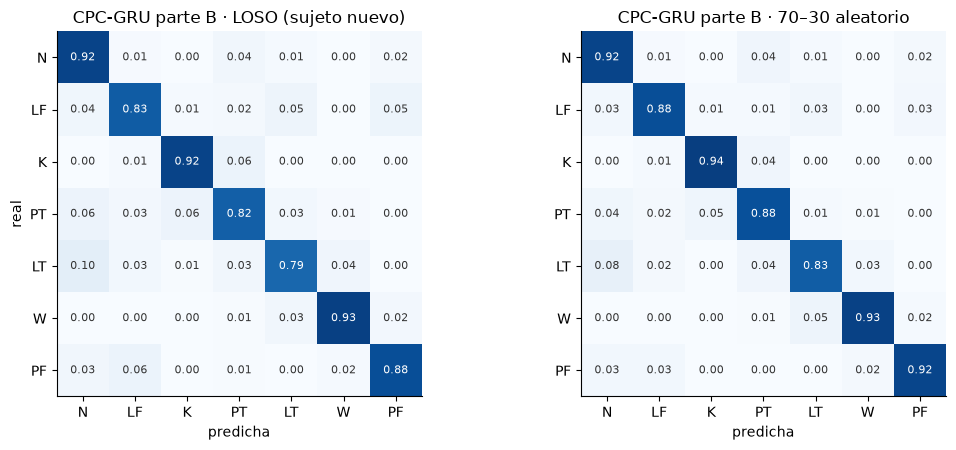

In [24]:
per_class_f1 = lambda runs: f1_score(pooled(runs, "y"), pooled(runs, "pred"), average=None, labels=range(len(LABELS)))
per_class_b = pd.DataFrame({
    "GRU A LOSO": per_class_f1(loso_runs), "GRU A 70–30": per_class_f1(gru_runs.values()),
    "GRU B LOSO": per_class_f1(gru_b["loso"].values()), "GRU B 70–30": per_class_f1(gru_b["70_30"].values()),
    "RF B LOSO": per_class_f1(rf_b["loso"].values()), "RF B 70–30": per_class_f1(rf_b["70_30"].values())},
    index=pd.Index(LABELS, name="clase"))
display(per_class_b.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (title, runs) in zip(axes, [("LOSO (sujeto nuevo)", list(gru_b["loso"].values())), ("70–30 aleatorio", list(gru_b["70_30"].values()))]):
    cm = confusion_matrix(pooled(runs, "y"), pooled(runs, "pred"), labels=range(len(LABELS)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.6 else "#333")
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("predicha")
    ax.set_title(f"CPC-GRU parte B · {title}")
axes[0].set_ylabel("real")
plt.tight_layout()
plt.show()

# 15. Conclusiones de la parte B

**Respuesta corta:** con las ventanas del artículo (1 s, sin traslape) y las 30 variables + sEMG, el mejor 70–30 que obtenemos es **0.928** (Random Forest). Sigue a ≈ 3 puntos del 95.7 % del artículo. El salto entre protocolos vuelve a ser pequeño (+2 a +3 puntos), igual que en la parte A. El hallazgo más útil no es sobre el protocolo: **el Random Forest con 30 variables + sEMG da el mejor LOSO del proyecto (0.908)**, mientras que CPC-GRU empeora con ventanas de 1 s (0.861).

| | LOSO | 70–30 | diferencia |
|---|---|---|---|
| CPC-GRU, parte A (4 s, EML) | 0.873 | 0.900 | +0.027 |
| CPC-GRU, parte B (1 s, 30 + sEMG) | 0.861 | 0.891 | +0.031 |
| Random Forest, parte A (4 s, EML) | 0.892 | 0.919 | +0.028 |
| Random Forest, parte B (1 s, 30 + sEMG) | **0.908** | **0.928** | +0.020 |
| BiLSTM (artículo) | 0.903 (un sujeto) | 0.957 | +0.054 |

## 15.1 El protocolo explica poco, también con las ventanas del artículo

- **Sin traslape, la fuga cambia de forma pero no desaparece.** Ninguna ventana de prueba comparte instantes con una de entrenamiento, pero el **90 %** tiene en entrenamiento el segundo inmediatamente anterior o el siguiente del mismo ensayo, y el 47 % tiene los dos.
- **Aun así, el 70–30 sube sólo 2–3 puntos**, como en la parte A. En el artículo sube 5.4–6.7. Igualar ventanas, variables y sEMG no reproduce su salto.
- **El modelo sigue sin memorizar.** CPC-GRU tiene un F1 en entrenamiento de 0.904 y en prueba de 0.891 en el 70–30. Como en la parte A, el límite no es de capacidad.

## 15.2 Por qué seguimos lejos del 95.7 %

Ya se igualaron la ventana, el traslape, las variables de movimiento y la sEMG. Quedan diferencias que este notebook no puede probar:

1. **Resolución:** el artículo trabaja a 240 Hz (240 muestras por ventana); nosotros a 12 Hz (12). Una ventana de 1 s a 12 Hz tiene muy poca forma de onda.
2. **Sujetos:** el artículo usa los 14, y en el 70–30 todos están en entrenamiento y en prueba; nosotros usamos 12.
3. **Balanceo con ruido:** el artículo replica ventanas con ruido gaussiano para balancear las clases y no aclara si lo hace antes o después de dividir. Si fue antes, su prueba contiene copias ruidosas de ventanas de entrenamiento, una fuga más fuerte que la nuestra.
4. **Etiquetado y segmentación** propios del artículo, que no conocemos en detalle.

Con lo medido aquí, **ni el protocolo ni la elección de ventanas explican por sí solos el 95.7 %**. Lo comparable con nuestro LOSO sigue siendo su 90.3 % en un sujeto, y el Random Forest de la parte B (0.908, promedio de 12 sujetos) ya está a ese nivel.

## 15.3 Random Forest con 30 variables + sEMG: el mejor LOSO del proyecto

- **0.908 ± 0.028**, contra 0.892 con `EML` (+0.016; mejora en 9 de 12 sujetos; p = 0.027) y 0.894 con las 30 variables en ventanas de 4 s (notebook 11).
- Es el modelo con mejor F1 en LOSO en las clases difíciles: LF 0.899, LT 0.878 y PT 0.865, contra 0.837, 0.823 y 0.821 de CPC-GRU en la parte A (no se guardó el F1 por clase del Random Forest de la parte A).
- **Limitación:** la parte B cambia a la vez la ventana (1 s) y las entradas (30 variables + sEMG). No se puede saber cuánto aporta cada cambio. Para separarlo haría falta una ablación: RF con 1 s y `EML`, y RF con 4 s y 30 variables + sEMG.
- **Costo:** se pierde la reducción de sensores del notebook 11 (11 sensores) y se agrega el equipo de sEMG.

## 15.4 CPC-GRU no se beneficia de las ventanas cortas

- **LOSO 0.861**, contra 0.873 en la parte A: −0.012, mejora sólo en 4 de 12 sujetos (p = 0.20). El sujeto 4 cae de 0.908 a 0.821.
- **El Random Forest le gana en los 12 sujetos** de la parte B (+0.047, p < 0.001), una brecha mayor que en la parte A (+0.019).
- **Explicación probable:** con 12 pasos, la GRU tiene muy poco contexto, y CPC sólo puede predecir 4 pasos (333 ms) en lugar de 1 s. La ventaja del modelo secuencial es integrar la historia del movimiento, y una ventana de 1 s la corta. Empeora justo en las actividades que dependen de la secuencia: LT (0.797 contra 0.823) y PF (0.844 contra 0.889). El Random Forest, que resume cada ventana con estadísticas, no depende de ese contexto.
- La sEMG y las 22 variables extra no compensan la pérdida de contexto para CPC-GRU.

## 15.5 Qué significa para el proyecto

- **La comparación con el artículo queda cerrada.** Con nuestro protocolo, nuestros modelos y casi todas sus condiciones, el 70–30 llega a 0.93, no a 0.96. La diferencia restante no está en la cabeza (notebook 13), ni en el pooling (notebook 14), ni en el protocolo o las ventanas (este notebook).
- **Para CPC-GRU, mantener las ventanas de 4 s** y el subconjunto `EML`.
- **Para la decisión de sensores,** el Random Forest de la parte B muestra que la sEMG y las variables completas sí aportan ≈ 1.5 puntos en LOSO. Que valga la pena depende de si ese punto y medio justifica el equipo adicional.
- **El argumento a favor de CPC no puede ser el F1 con todas las etiquetas**, donde el Random Forest gana en las dos configuraciones. Tiene que ser la eficiencia con pocas etiquetas, que es lo que evalúa el notebook 16.